# Data pipeline

How MedSegBench data is pulled, configured, and turned into batches. It's all driven by one `DataConfig`... a small YAML file in `configs/data/`

In [1]:
import sys
sys.path.insert(0, "../src")

from medseg.data.medseg_data import (
    DataConfig, build_dataloaders, list_datasets, resolve_dataset_class,
)

/home/renzo/miniconda3/envs/sam-medseg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load a config

Each dataset is one YAML file. Load it into a `DataConfig`:

In [2]:
cfg = DataConfig.from_yaml("../configs/data/busi.yaml")
cfg

DataConfig(name='busi', size=256, root='~/.medsegbench', download=True, category=None, n_train=None, subset_seed=0, force_rgb=True, img_size=256, normalize=None, aug_preset='medseg_default', batch_size=8, num_workers=4, pin_memory=True, seed=42)

**Main options** (edit the YAML, or set them in code):

- `name` — which dataset, e.g. `busi`, `kvasir`
- `size` — resolution to download: `128` / `256` / `512`
- `img_size` — square size after resize + pad
- `normalize` — `None` (/255) or `"imagenet"`
- `aug_preset` — `"medseg_default"` (augment) or `"none"`
- `n_train` — train on only N images (`None` = all)
- `batch_size`, `num_workers`, `seed`

You can also build one directly instead of from YAML:

In [3]:
DataConfig(name="kvasir", img_size=512, aug_preset="none", batch_size=4)

DataConfig(name='kvasir', size=256, root='~/.medsegbench', download=True, category=None, n_train=None, subset_seed=0, force_rgb=True, img_size=512, normalize=None, aug_preset='none', batch_size=4, num_workers=4, pin_memory=True, seed=42)

## 2. Available datasets

`list_datasets()` lists every dataset as `(class, task, channels, #classes)`. Any short name, class name, or flag works for `name`

In [4]:
list_datasets()

[('Bbbc010MSBench', 'binary', 1, 2),
 ('BriFiSegMSBench', 'binary', 1, 2),
 ('BusiMSBench', 'binary', 1, 2),
 ('CellnucleiMSBench', 'binary', 3, 2),
 ('ChaseDB1MSBench', 'binary', 3, 2),
 ('ChuacMSBench', 'binary', 1, 2),
 ('Covid19RadioMSBench', 'binary', 1, 2),
 ('CovidQUExMSBench', 'binary', 1, 2),
 ('CystoFluidMSBench', 'binary', 3, 2),
 ('Dca1MSBench', 'binary', 1, 2),
 ('DeepbacsMSBench', 'binary', 1, 2),
 ('DriveMSBench', 'binary', 3, 2),
 ('DynamicNuclearMSBench', 'binary', 1, 2),
 ('IdribMSBench', 'binary', 3, 2),
 ('Isic2016MSBench', 'binary', 3, 2),
 ('Isic2018MSBench', 'binary', 3, 2),
 ('KvasirMSBench', 'binary', 3, 2),
 ('MosMedPlusMSBench', 'binary', 3, 2),
 ('NucleiMSBench', 'binary', 3, 2),
 ('NusetMSBench', 'binary', 1, 2),
 ('PandentalMSBench', 'binary', 1, 2),
 ('PolypGenMSBench', 'binary', 3, 2),
 ('Promise12MSBench', 'binary', 1, 2),
 ('RoboToolMSBench', 'binary', 3, 2),
 ('TnbcnucleiMSBench', 'binary', 3, 2),
 ('USforKidneyMSBench', 'binary', 1, 2),
 ('UWSkinCanc

In [5]:
resolve_dataset_class("busi")   # -> BusiMSBench

medsegbench.dataset.BusiMSBench

## 3. Build the loaders

`build_dataloaders(cfg)` returns `{train, val, test}`. The first call downloads the dataset into `cfg.root` (when `download: true`)...

In [6]:
loaders = build_dataloaders(cfg)
{split: len(dl.dataset) for split, dl in loaders.items()}

{'train': 452, 'val': 64, 'test': 131}

## 4. A batch

Every dataset yields the same dict. Images are `(B, 3, H, W)` floats; binary masks are `(B, 1, H, W)` in {0, 1}

In [7]:
batch = next(iter(loaders["train"]))
{k: (tuple(v.shape) if hasattr(v, "shape") else v) for k, v in batch.items()}

{'image': (8, 3, 256, 256),
 'mask': (8, 1, 256, 256),
 'task': ['binary',
  'binary',
  'binary',
  'binary',
  'binary',
  'binary',
  'binary',
  'binary'],
 'num_classes': (8,),
 'dataset': ['BusiMSBench',
  'BusiMSBench',
  'BusiMSBench',
  'BusiMSBench',
  'BusiMSBench',
  'BusiMSBench',
  'BusiMSBench',
  'BusiMSBench'],
 'index': (8,)}

## 5. View one sample

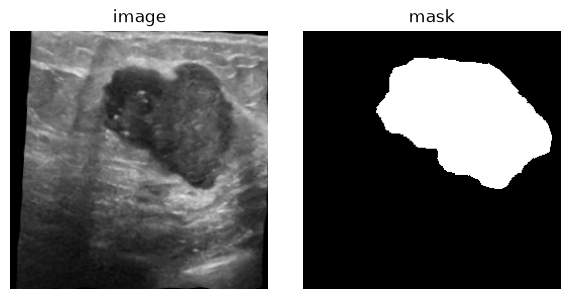

In [10]:
import matplotlib.pyplot as plt

idx = 1

img = batch["image"][idx].permute(1, 2, 0).clip(0, 1)   # (H, W, 3)
msk = batch["mask"][idx, 0]                          # (H, W)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(img);             ax[0].set_title("image"); ax[0].axis("off")
ax[1].imshow(msk, cmap="gray"); ax[1].set_title("mask");  ax[1].axis("off")
plt.tight_layout()